In [5]:
from pathlib import Path
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from enums import *
from contract import EuropeanContract
from market_data import MarketData
from model import FlatVolModel
from pricer import EuropeanAnalyticPricer, Params, Pricer

In [8]:
if not (MarketData.market_folder / MarketData.filename_spot).exists():
    local_mkt = Path("mkt").resolve()
    if (local_mkt / MarketData.filename_spot).exists():
        MarketData.market_folder = local_mkt

MarketData.initialize()

underlying = Stock.BLUECHIP_BANK
model = FlatVolModel(underlying)
params = Params()
spot = model.spot

print(f"Market Environment Initialized: {underlying.value}")
print(f"Spot price: {spot:.2f}, Risk-free rate: {model.risk_free_rate:.2%}")

Market Environment Initialized: BLUECHIP_BANK
Spot price: 130.17, Risk-free rate: 5.00%


In [9]:
Pricer.fd_method = FiniteDifferenceMethod.CENTRAL
Pricer.bump_type = BumpType.RELATIVE
Pricer.bump_size = 0.0001

def _get_spot_bump_amount(self) -> float:
    if self.bump_type == BumpType.RELATIVE:
        return self.bump_size * self.model.spot
    elif self.bump_type == BumpType.ABSOLUTE:
        return self.bump_size
    raise ValueError(f"Unsupported BumpType: {self.bump_type}")

def _calc_delta_numerical(self, method: GreekMethod) -> float:
    if method != GreekMethod.BUMP:
        return self.calc_delta(method)
    
    h = self._get_spot_bump_amount()
    v0 = self.calc_fair_value()
    
    if self.fd_method == FiniteDifferenceMethod.CENTRAL:
        m_up = copy.deepcopy(self.model)
        m_up.bump_spot(h)
        v_up = self.create_pricer(self.contract, m_up, self.params).calc_fair_value()
        
        m_down = copy.deepcopy(self.model)
        m_down.bump_spot(-h)
        v_down = self.create_pricer(self.contract, m_down, self.params).calc_fair_value()
        return (v_up - v_down) / (2.0 * h)
        
    elif self.fd_method == FiniteDifferenceMethod.FORWARD:
        m_up = copy.deepcopy(self.model)
        m_up.bump_spot(h)
        v_up = self.create_pricer(self.contract, m_up, self.params).calc_fair_value()
        return (v_up - v0) / h
        
    elif self.fd_method == FiniteDifferenceMethod.BACKWARD:
        m_down = copy.deepcopy(self.model)
        m_down.bump_spot(-h)
        v_down = self.create_pricer(self.contract, m_down, self.params).calc_fair_value()
        return (v0 - v_down) / h
    else:
        raise ValueError(f"Unsupported FiniteDifferenceMethod: {self.fd_method}")

def _calc_gamma_numerical(self, method: GreekMethod) -> float:
    if method != GreekMethod.BUMP:
        return self.calc_gamma(method)
    
    h = self._get_spot_bump_amount()
    v0 = self.calc_fair_value()
    
    m_up = copy.deepcopy(self.model)
    m_up.bump_spot(h)
    v_up = self.create_pricer(self.contract, m_up, self.params).calc_fair_value()
    
    m_down = copy.deepcopy(self.model)
    m_down.bump_spot(-h)
    v_down = self.create_pricer(self.contract, m_down, self.params).calc_fair_value()
    
    return (v_up - 2.0 * v0 + v_down) / (h ** 2)

Pricer._get_spot_bump_amount = _get_spot_bump_amount
Pricer.calc_delta_bump = _calc_delta_numerical
Pricer.calc_gamma_bump = _calc_gamma_numerical

In [10]:
Pricer.fd_method = FiniteDifferenceMethod.CENTRAL
Pricer.bump_type = BumpType.RELATIVE
Pricer.bump_size = 0.0001

strikes = [spot * 0.85, spot, spot * 1.15]
expiries = [0.25, 0.5, 1.0, 2.0]
opt_types = [PutCallFwd.CALL, PutCallFwd.PUT]

records = []

for o_type in opt_types:
    for K in strikes:
        if (o_type == PutCallFwd.CALL and K < spot) or (o_type == PutCallFwd.PUT and K > spot):
            moneyness = "ITM"
        elif K == spot:
            moneyness = "ATM"
        else:
            moneyness = "OTM"

        for T in expiries:
            contract = EuropeanContract(
                underlying=underlying,
                derivative_type=o_type,
                long_short=LongShort.LONG,
                strike=K,
                expiry=T
            )
            pricer = EuropeanAnalyticPricer(contract, model, params)

            d_ana = pricer.calc_delta(GreekMethod.ANALYTIC)
            d_num = pricer.calc_delta_bump(GreekMethod.BUMP)

            g_ana = pricer.calc_gamma(GreekMethod.ANALYTIC)
            g_num = pricer.calc_gamma_bump(GreekMethod.BUMP)

            records.append({
                'Type': o_type.value,
                'Moneyness': moneyness,
                'Strike': round(K, 2),
                'Expiry': T,
                'Delta (Ana)': d_ana,
                'Delta (Num)': d_num,
                'Delta Err': abs(d_ana - d_num),
                'Gamma (Ana)': g_ana,
                'Gamma (Num)': g_num,
                'Gamma Err': abs(g_ana - g_num)
            })

df_results = pd.DataFrame(records)
pd.set_option('display.float_format', lambda x: f'{x:.6f}')
print("\n[1] Comparison Table across Portfolio of European Options:")
display(df_results)
print(f"Max Delta Error: {df_results['Delta Err'].max():.2e}")
print(f"Max Gamma Error: {df_results['Gamma Err'].max():.2e}")


[1] Comparison Table across Portfolio of European Options:


,Type,Moneyness,Strike,Expiry,Delta (Ana),Delta (Num),Delta Err,Gamma (Ana),Gamma (Num),Gamma Err
0,CALL,ITM,110.640000,0.250000,0.807146,0.807146,0.000000,0.009026,0.009026,0.000000
1,CALL,ITM,110.640000,0.500000,0.776975,0.776975,0.000000,0.007430,0.007430,0.000000
2,CALL,ITM,110.640000,1.000000,0.757845,0.757845,0.000000,0.005378,0.005378,0.000000
3,CALL,ITM,110.640000,2.000000,0.766809,0.766809,0.000000,0.003593,0.003593,0.000000
4,CALL,ATM,130.170000,0.250000,0.563153,0.563153,0.000000,0.017252,0.017252,0.000000
5,CALL,ATM,130.170000,0.500000,0.588667,0.588667,0.000000,0.012493,0.012493,0.000000
6,CALL,ATM,130.170000,1.000000,0.626163,0.626163,0.000000,0.007642,0.007642,0.000000
7,CALL,ATM,130.170000,2.000000,0.678952,0.678952,0.000000,0.004652,0.004652,0.000000
8,CALL,OTM,149.700000,0.250000,0.222739,0.222739,0.000000,0.015100,0.015100,0.000000
9,CALL,OTM,149.700000,0.500000,0.327656,0.327656,0.000000,0.013310,0.013310,0.000000


Max Delta Error: 1.32e-08
Max Gamma Error: 5.85e-10


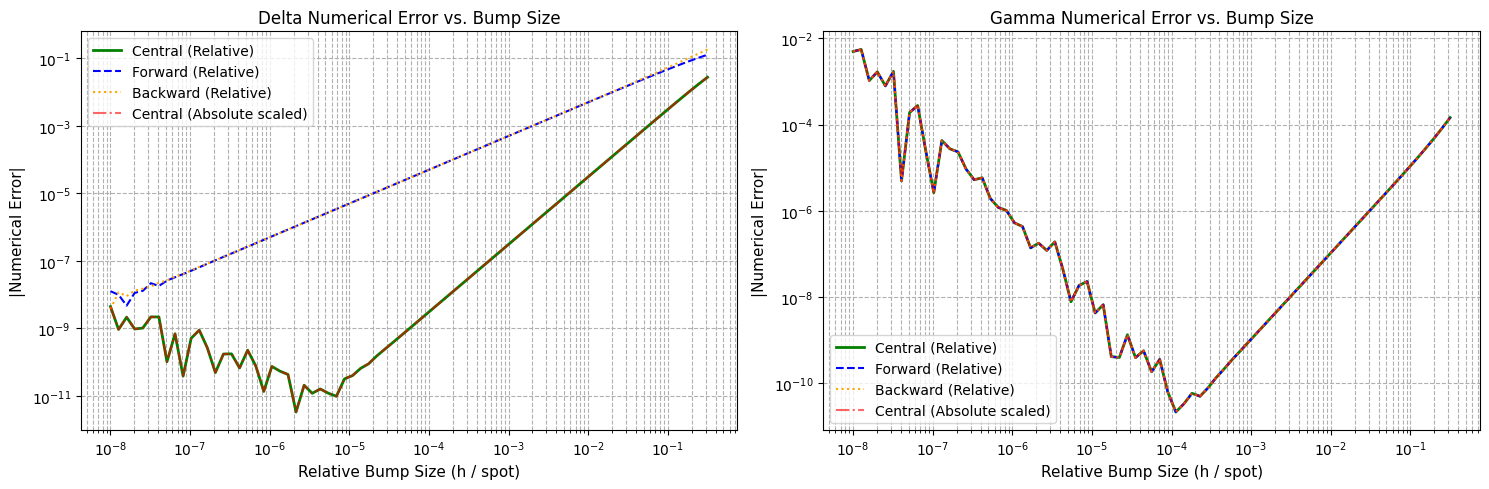

In [11]:
atm_contract = EuropeanContract(underlying, PutCallFwd.CALL, LongShort.LONG, spot, 1.0)
benchmark_pricer = EuropeanAnalyticPricer(atm_contract, model, params)

exact_delta = benchmark_pricer.calc_delta(GreekMethod.ANALYTIC)
exact_gamma = benchmark_pricer.calc_gamma(GreekMethod.ANALYTIC)

bump_range = np.logspace(-8, -0.5, 75)

delta_errors = {'Central_Rel': [], 'Forward_Rel': [], 'Backward_Rel': [], 'Central_Abs': []}
gamma_errors = {'Central_Rel': [], 'Forward_Rel': [], 'Backward_Rel': [], 'Central_Abs': []}

for b in bump_range:
    Pricer.bump_type = BumpType.RELATIVE
    Pricer.bump_size = b
    
    Pricer.fd_method = FiniteDifferenceMethod.CENTRAL
    delta_errors['Central_Rel'].append(abs(benchmark_pricer.calc_delta_bump(GreekMethod.BUMP) - exact_delta))
    gamma_errors['Central_Rel'].append(abs(benchmark_pricer.calc_gamma_bump(GreekMethod.BUMP) - exact_gamma))
    
    Pricer.fd_method = FiniteDifferenceMethod.FORWARD
    delta_errors['Forward_Rel'].append(abs(benchmark_pricer.calc_delta_bump(GreekMethod.BUMP) - exact_delta))
    gamma_errors['Forward_Rel'].append(abs(benchmark_pricer.calc_gamma_bump(GreekMethod.BUMP) - exact_gamma))
    
    Pricer.fd_method = FiniteDifferenceMethod.BACKWARD
    delta_errors['Backward_Rel'].append(abs(benchmark_pricer.calc_delta_bump(GreekMethod.BUMP) - exact_delta))
    gamma_errors['Backward_Rel'].append(abs(benchmark_pricer.calc_gamma_bump(GreekMethod.BUMP) - exact_gamma))
    
    Pricer.bump_type = BumpType.ABSOLUTE
    Pricer.bump_size = b * spot
    Pricer.fd_method = FiniteDifferenceMethod.CENTRAL
    delta_errors['Central_Abs'].append(abs(benchmark_pricer.calc_delta_bump(GreekMethod.BUMP) - exact_delta))
    gamma_errors['Central_Abs'].append(abs(benchmark_pricer.calc_gamma_bump(GreekMethod.BUMP) - exact_gamma))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].loglog(bump_range, delta_errors['Central_Rel'], label='Central (Relative)', color='green', lw=2)
axes[0].loglog(bump_range, delta_errors['Forward_Rel'], label='Forward (Relative)', color='blue', ls='--')
axes[0].loglog(bump_range, delta_errors['Backward_Rel'], label='Backward (Relative)', color='orange', ls=':')
axes[0].loglog(bump_range, delta_errors['Central_Abs'], label='Central (Absolute scaled)', color='red', ls='-.', alpha=0.6)
axes[0].set_title("Delta Numerical Error vs. Bump Size", fontsize=12)
axes[0].set_xlabel("Relative Bump Size (h / spot)", fontsize=11)
axes[0].set_ylabel("|Numerical Error|", fontsize=11)
axes[0].grid(True, which="both", ls="--")
axes[0].legend()

axes[1].loglog(bump_range, gamma_errors['Central_Rel'], label='Central (Relative)', color='green', lw=2)
axes[1].loglog(bump_range, gamma_errors['Forward_Rel'], label='Forward (Relative)', color='blue', ls='--')
axes[1].loglog(bump_range, gamma_errors['Backward_Rel'], label='Backward (Relative)', color='orange', ls=':')
axes[1].loglog(bump_range, gamma_errors['Central_Abs'], label='Central (Absolute scaled)', color='red', ls='-.', alpha=0.6)
axes[1].set_title("Gamma Numerical Error vs. Bump Size", fontsize=12)
axes[1].set_xlabel("Relative Bump Size (h / spot)", fontsize=11)
axes[1].set_ylabel("|Numerical Error|", fontsize=11)
axes[1].grid(True, which="both", ls="--")
axes[1].legend()

plt.tight_layout()
plt.show()

There is a U-shaped error curve:
   - h > 0.01: The approximation fails because option prices 
     curve, but finite difference treats the curve like a straight line. Central 
     difference handles this much better than forward/backward schemes.
   - h < 0.000001: Computers lose precision when subtracting 
     two nearly identical numbers. Dividing by a tiny h (or h^2) blows up this 
     rounding noise.

Absolute vs. relative steps:
   - Absolute: This is inconsistent, since a $1 move is huge (10%) on a $10 
     stock, but tiny (0.05%) on a $2,000 stock.
   - Relative: Consistent, because scales automatically with any asset 
     price. Always use relative bumping.

Recommended bump sizes:
   - Delta: h = 0.0001 to 0.00001
   - Gamma: h = 0.001 to 0.0001 
   (Gamma needs a larger step because dividing by h^2 amplifies rounding errors much faster.)